# Predictores aprendidos servidos en vivo desde un documento portable: la misma predicción en Python y en el navegador

**Pregunta:** ¿Se puede servir un modelo aprendido desde un documento portable con exactamente las predicciones del motor?

**Nivel 4: Más allá del estado del arte** · Requiere: 05-learned-arms/01-fitting-a-learned-arm-on-nine-sites, 06-design-response/02-a-burden-and-spacing-surface · Tiempo de lectura: unos 35 minutos

## Objetivos

La aplicación web recalcula cada modelo, los aprendidos incluidos, sobre un diseño que cambia el lector, sin un servidor de Python detrás. Eso es posible porque cada predictor aprendido se exporta una vez a un documento JSON portable que un navegador puede evaluar (afirmación BS-5 del documento de diseño). La afirmación solo vale si el documento da la misma predicción que el motor. Este notebook exporta predictores por sí mismo, lee los documentos con el lector de referencia del motor, y mide la diferencia.

Al terminar habrá:

- ajustado gradient boosting sin Enusa, lo habrá exportado con `export_arm` y mirado dentro del documento;
- comparado la predicción portable con la del motor en los 97 tiros, entre ellos los 12 de Enusa que el modelo nunca vio;
- exportado los otros cuatro predictores aprendidos y medido tamaño y diferencia de cada uno, y seguido una palanca de diseño a través del documento;
- alterado el documento versionado del ámbito Enusa, visto qué hace su dirección de contenido, y comprobado que una exportación nueva iguala a la versionada.

## Preparación

Instale los paquetes con los pines exactos de `notebooks/requirements.txt`. El motor es `blastfrag`, publicado en PyPI; los otros paquetes son su base numérica y la biblioteca de gráficos.

```bash
pip install blastfrag==0.4.0 numpy==2.5.4 matplotlib==3.11.2
```

La celda de preparación importa los paquetes, la herramienta de variantes `apply_variant` del producto y su función `digest` (la dirección de contenido de los archivos de modelos versionados), imprime las versiones, carga el corpus y deja fuera a Enusa: `fit_rows` son los 85 tiros de las otras nueve campañas. También define `Table`.

In [1]:
# Importaciones, versiones de los paquetes y el cargador del corpus
from importlib.metadata import version
from pathlib import Path
import copy
import json
import sys

sys.path.insert(0, str(Path("../../../data-pipeline")))
from pipeline.cases.fragmenta_cases import Variant
from pipeline.model.blasts import apply_variant
from pipeline.stages.export import digest

import blastfrag as bf
import matplotlib.pyplot as plt
import numpy as np

for name in ("blastfrag", "numpy", "matplotlib"):
    print(f"{name}=={version(name)}")

DERIVED = Path("../../../data/derived")
train = bf.load_training_corpus()
print(len(train), "tiros de", len({b.site for b in train}), "campañas")

class Table:
    """Filas bajo un encabezado, mostradas como tabla Markdown"""

    def __init__(self, header, rows):
        self.header = list(header)
        self.rows = [[str(cell) for cell in row] for row in rows]

    def _repr_markdown_(self):
        lines = ["| " + " | ".join(self.header) + " |", "|" + "---|" * len(self.header)]
        lines += ["| " + " | ".join(row) + " |" for row in self.rows]
        return "\n".join(lines)

    __repr__ = _repr_markdown_

held_out_site = "Enusa"
fit_rows = [blast for blast in train if blast.site != held_out_site]

blastfrag==0.4.0
numpy==2.5.4
matplotlib==3.11.2
97 tiros de 10 campañas


## Datos

| Fuente | Titular y URL | Clase de licencia | Archivo que lee el notebook |
|---|---|---|---|
| Las filas de entrenamiento | Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 | hechos numéricos reutilizados con cita; el artículo nunca se distribuye | el corpus dentro del paquete `blastfrag` |
| El archivo de modelos del ámbito Enusa: los siete predictores ajustados sin ningún tiro de Enusa | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/models/Enusa.json`, para la alteración y la comprobación final |
| El índice, que lista cada archivo de modelos con su resumen | este repositorio (MIT), escrito por la ejecución offline | la licencia propia del producto | `data/derived/manifests/index.json` |

El lector del formato portable es `bf.predict_portable`, en el motor. El navegador tiene su propio lector en TypeScript, que la prueba del producto `frontend/test/parity.test.ts` contrasta con los documentos versionados.

## Método

Un predictor aprendido ajustado no es un pickle ni un servidor de modelos. El motor lo escribe como un documento JSON en un esquema versionado (`blastfrag.portable/v1`) que guarda exactamente lo que necesita una predicción: para el bosque y el modelo con boosting los árboles como arreglos de hijos izquierdo y derecho, variables y umbrales de división; las constantes de estandarización; para el regresor de vectores de soporte los vectores de soporte y los coeficientes duales; para la red los pesos de las capas; para el conjunto de apilamiento una referencia al bosque y al modelo con boosting más el metaaprendiz. Evaluar el documento requiere solo aritmética, así que un lector escrito en TypeScript puede reproducirlo en un navegador.

La afirmación BS-5 tiene tres partes, y cada una se mide más abajo: el documento predice lo que predice el motor (pasos 2 y 3), sigue un diseño que cambia el lector (paso 4), y un documento viejo o editado no puede pasar por el versionado (paso 5 y la comprobación). La diferencia entre dos lectores de la misma función se mide en metros, como la mayor diferencia absoluta sobre los 97 tiros.

## Estado del arte

- Los predictores aprendidos publicados para este corpus se informan mediante sus puntajes y sus parámetros: los anchos de la red (Kulatilake et al. 2012, https://doi.org/10.1007/s10706-012-9496-3), los núcleos y constantes de los vectores de soporte (Amoako et al. 2022, https://doi.org/10.3390/mining2020013; Sui et al. 2025, https://doi.org/10.3390/app15031254) y la tasa de aprendizaje de boosting (Sui et al. 2025).
- Las fuentes reunidas para este trabajo no dan una forma ejecutable de ninguno que un lector pueda aplicar a un diseño nuevo. Quien quiere la predicción para un diseño tiene que reentrenar el modelo desde los parámetros, como hace el notebook 03 del tema 05 con la red.
- La forma convencional de servir un modelo aprendido es un proceso de Python detrás de una API, que el despliegue estático del producto no tiene.

Así que el estado del arte ofrece un puntaje y una receta, no una función que un navegador pueda llamar. La afirmación que va más allá es que la función ajustada misma puede enviarse, y los pasos siguientes la prueban.

## Más allá del estado del arte

### Paso 1: ajustar, exportar y mirar adentro

La celda ajusta gradient boosting con los 85 tiros fuera de Enusa (el mismo ajuste del ámbito Enusa del producto), lo exporta con `export_arm`, serializa el documento e imprime lo que contiene: el esquema, el tipo de modelo, el número de árboles, el tamaño del primer árbol y del archivo completo, y el nodo raíz del primer árbol.

In [2]:
# Ajustar gradient boosting sin Enusa y exportarlo a un documento portable
model = bf.default_arms()["xgboost"]().fit(fit_rows)
document = bf.export_arm(model)
text = json.dumps(document)
trees = document["trees"]
print("esquema:", document["schema"], "| tipo:", document["kind"], "| motor:", document["engine_version"])
print("árboles:", len(trees), "| nodos en el primer árbol:", len(trees[0]["t"]), "| tamaño del JSON:", len(text),
    "caracteres")
print("primer árbol, raíz:", {key: values[0] for key, values in trees[0].items()})
print("la raíz divide por:", document["features"][trees[0]["feature"][0]])

esquema: blastfrag.portable/v1 | tipo: xgboost | motor: 0.04.000
árboles: 100 | nodos en el primer árbol: 29 | tamaño del JSON: 40032 caracteres
primer árbol, raíz: {'left': 1, 'right': 2, 'feature': 6, 't': 1.36735999584198}
la raíz divide por: E_GPa


**Qué muestra la salida.** El modelo completo son 100 árboles, el primero con 29 nodos, en 40,032 caracteres de JSON. Cada nodo son cuatro números: los hijos `left` y `right`, el índice de la variable `feature` por la que se divide y `t`, el umbral de una división o el valor de una hoja. La raíz divide por el módulo de la roca, la variable que nombra la salida, en el umbral 1,367 (las entradas se estandarizan antes, con constantes que lleva el documento). Nada de esto necesita Python: recorrer los árboles es un bucle sobre arreglos. **Qué no muestra:** que el recorrido dé la respuesta del motor, que es el paso siguiente.

### Paso 2: la predicción portable contra la del motor

`predict_portable` es el lector de referencia. La celda predice los 97 tiros del corpus dos veces, con el modelo ajustado del propio motor y solo con el documento, y toma la diferencia. Los 12 tiros de Enusa son aquellos con los que no se entrenó el modelo, así que prueban el documento donde una copia vieja de los datos de entrenamiento no ayudaría.

In [3]:
# Evaluar el documento con el lector de referencia en los 97 tiros y compararlo con la predicción del propio motor
engine = np.array([p.x50_m for p in model.predict(train)])
portable = np.array([bf.predict_portable(document, blast)[0] for blast in train])
residual = portable - engine
print("tiros comparados:", len(train), "| mayor diferencia absoluta:", f"{np.abs(residual).max():.1e}", "m")
print("tiros cuyas dos predicciones son idénticas bit a bit:", int((residual == 0).sum()))

tiros comparados: 97 | mayor diferencia absoluta: 0.0e+00 m
tiros cuyas dos predicciones son idénticas bit a bit: 97


La celda siguiente grafica la predicción portable contra la del motor para los 97 tiros, los 85 de entrenamiento en azul y los 12 de Enusa excluidos como cuadrados naranjas, con la línea de identidad. Si el lector fuera solo aproximadamente correcto, los puntos se saldrían de la línea.

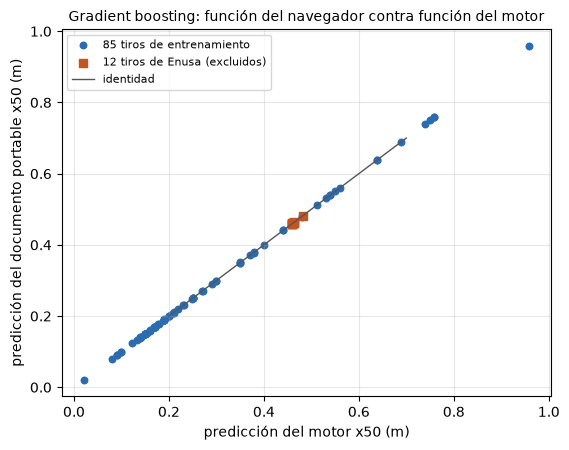

In [4]:
# Predicción portable contra la del motor para los 97 tiros; naranja: la campaña que el modelo nunca vio
unseen = np.array([blast.site == held_out_site for blast in train])
fig, ax = plt.subplots(figsize=(5.8, 4.6))
ax.scatter(engine[~unseen], portable[~unseen], s=22, color="#2b6cb0", label="85 tiros de entrenamiento")
ax.scatter(engine[unseen], portable[unseen], s=30, marker="s", color="#c05621", label="12 tiros de Enusa (excluidos)")
ax.plot([0.2, 0.7], [0.2, 0.7], color="#555", lw=1, label="identidad")
ax.set_xlabel("predicción del motor x50 (m)")
ax.set_ylabel("predicción del documento portable x50 (m)")
ax.set_title("Gradient boosting: función del navegador contra función del motor", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Los 97 puntos están sobre la línea de identidad: azules los 85 tiros de entrenamiento y cuadrados naranjas los 12 de Enusa que el modelo nunca vio, que caen sobre la misma línea. La salida de arriba dice por qué: la mayor diferencia absoluta es 0.0e+00 m y las 97 predicciones son idénticas bit a bit, porque el lector recorre los mismos árboles y suma los mismos valores de hoja. **Qué no muestra:** exactitud. La paridad dice que el navegador calcula la misma función, no que la función sea correcta. **Qué se sigue:** para boosting el documento es el modelo, exactamente.

### Paso 3: los otros predictores aprendidos

La celda repite la exportación para la red, el regresor de vectores de soporte radial, el bosque y el conjunto de apilamiento. Para cada uno guarda la diferencia absoluta con el motor en cada tiro, y mide el tamaño del documento. Demora cerca de diez segundos. La aritmética difiere por tipo: los árboles solo comparan y suman números guardados, mientras que la red y el regresor de vectores de soporte evalúan exponenciales, donde el orden de las operaciones de coma flotante puede diferir en los últimos dígitos.

In [5]:
# Exportar los otros predictores aprendidos y medir la misma diferencia en cada tiro; unos diez segundos
factories = bf.default_arms()
exported = {}
residuals = {}
rows = []
for name in ("published-neural-net", "svr-rbf", "random-forest", "xgboost", "stacking"):
    fitted = factories[name]().fit(fit_rows)
    exported[name] = bf.export_arm(fitted)
    gaps = [abs(fitted.predict_one(b).x50_m - bf.predict_portable(exported[name], b)[0]) for b in train]
    residuals[name] = np.array(gaps)
    rows.append((name, exported[name]["kind"], len(json.dumps(exported[name])), residuals[name].max()))
Table(["predictor", "tipo de documento", "tamaño (caracteres)", "mayor diferencia (m)"],
      [(n, k, f"{s:,}", f"{g:.1e}") for n, k, s, g in rows])

| predictor | tipo de documento | tamaño (caracteres) | mayor diferencia (m) |
|---|---|---|---|
| published-neural-net | network | 24,782 | 8.9e-16 |
| svr-rbf | svr | 9,114 | 2.8e-15 |
| random-forest | forest | 168,687 | 0.0e+00 |
| xgboost | xgboost | 40,032 | 0.0e+00 |
| stacking | stacking | 208,192 | 0.0e+00 |

La celda siguiente dibuja dos cosas de los cinco documentos: su tamaño en un eje logarítmico, que es lo que descargaría un navegador, y la diferencia con el motor de cada tiro en otro eje logarítmico, donde 1e-17 representa un cero exacto. Mire qué documentos son grandes y cuáles no son exactos.

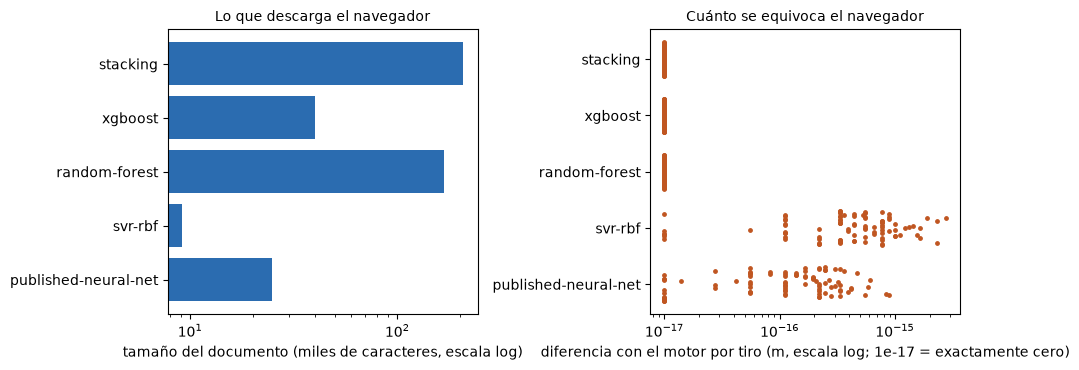

In [6]:
# Tamaño de cada documento portable y mayor diferencia con el motor
fig, (ax, bx) = plt.subplots(1, 2, figsize=(9.8, 3.8))
names = [row[0] for row in rows]
ax.barh(names, [row[2] / 1000 for row in rows], color="#2b6cb0")
ax.set_xscale("log")
ax.set_xlabel("tamaño del documento (miles de caracteres, escala log)")
ax.set_title("Lo que descarga el navegador", fontsize=10)
for k, name in enumerate(names):
    bx.scatter(np.maximum(residuals[name], 1e-17), np.full(len(train), k) + np.linspace(-0.3, 0.3, len(train)), s=6,
        color="#c05621")
bx.set_xscale("log")
bx.set_yticks(range(len(names)), names)
bx.set_xlabel("diferencia con el motor por tiro (m, escala log; 1e-17 = exactamente cero)")
bx.set_title("Cuánto se equivoca el navegador", fontsize=10)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Los documentos abarcan más de un factor de veinte en tamaño, de 9,114 caracteres para el regresor de vectores de soporte a 208,192 para el conjunto de apilamiento, que contiene el bosque y los árboles con boosting. El panel derecho muestra la diferencia con el motor para cada uno de los 97 tiros en un eje logarítmico donde 1e-17 representa exactamente cero: el bosque, boosting y el apilamiento están en cero, y la red y el regresor de vectores de soporte difieren como máximo en 8.9e-16 m y 2.8e-15 m, que es redondeo de coma flotante. **Qué no muestra:** un orden de los modelos, solo que servirlos no los cambia. **Qué se sigue:** una diferencia de un femtómetro no es una diferencia, y el navegador puede usar el documento de cualquiera de los cinco.

### Paso 4: mover una palanca de diseño

El sentido del documento es que la predicción siga un diseño que cambia el lector. La celda toma el tiro `En1` de Enusa, multiplica su razón de bordo por 25 factores de 0,7 a 1,3 con `apply_variant` del producto, y predice cada diseño con el documento y con un ajuste nuevo del motor, para gradient boosting y para el bosque aleatorio.

In [7]:
# Mover una palanca de diseño: multiplicador de bordo de 0.7 a 1.3 en el tiro En1, portable contra motor para dos
# predictores
blast = next(b for b in train if b.blast_id == "En1")
multipliers = np.linspace(0.7, 1.3, 25)
designs = [apply_variant(blast, Variant("sweep", "", "", "B_over_D", float(m))) for m in multipliers]
sweep = {}
for name in ("xgboost", "random-forest"):
    fitted = factories[name]().fit(fit_rows)
    engine_curve = [fitted.predict_one(d).x50_m for d in designs]
    portable_curve = [bf.predict_portable(exported[name], d)[0] for d in designs]
    sweep[name] = (engine_curve, portable_curve)
    print(f"{name:<14} mayor diferencia a lo largo del barrido:",
        f"{max(abs(a - b) for a, b in zip(*sweep[name])):.1e}", "m",
          f"| rango de la respuesta: {min(engine_curve):.4f} - {max(engine_curve):.4f} m")

xgboost        mayor diferencia a lo largo del barrido: 0.0e+00 m | rango de la respuesta: 0.4598 - 0.4601 m
random-forest  mayor diferencia a lo largo del barrido: 0.0e+00 m | rango de la respuesta: 0.4211 - 0.4338 m


La celda siguiente dibuja la respuesta de ambos predictores al multiplicador del bordo: el motor como línea de color y el documento portable como marcadores negros encima. Si el documento no siguiera el diseño, los marcadores se saldrían de la línea.

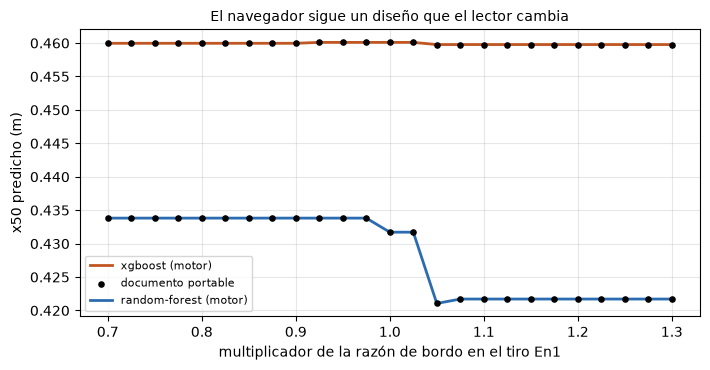

In [8]:
# La respuesta al bordo de ambos predictores, el motor como línea y el documento portable como marcadores
fig, ax = plt.subplots(figsize=(7.2, 3.8))
for (name, (engine_curve, portable_curve)), color in zip(sweep.items(), ("#c05621", "#2b6cb0")):
    ax.plot(multipliers, engine_curve, color=color, lw=2, label=f"{name} (motor)")
    ax.scatter(multipliers, portable_curve, color="black", s=14, zorder=3,
        label="documento portable" if color == "#c05621" else None)
ax.set_xlabel("multiplicador de la razón de bordo en el tiro En1")
ax.set_ylabel("x50 predicho (m)")
ax.set_title("El navegador sigue un diseño que el lector cambia", fontsize=10)
ax.legend(fontsize=8)
ax.grid(alpha=0.3)
fig.tight_layout()
plt.show()

**Qué muestra la figura.** Los marcadores negros (documento portable) están sobre ambas líneas (motor) en los 25 multiplicadores, con una mayor diferencia de 0.0e+00 m para los dos predictores. Ambas respuestas son escalones, que es como responden los modelos de árboles a un cambio suave: boosting se queda entre 0,4598 m y 0,4601 m, un escalón de un tercio de milímetro, y el bosque se mueve entre 0,4338 m y 0,4211 m, bajando a medida que se ensancha el bordo. **Qué no muestra:** que la respuesta tenga el tamaño o el sentido correctos; el bosque predice un diseño más grueso (un bordo más ancho) como algo más fino, lo que la ecuación clásica del notebook 01 de este tema no haría. **Qué se sigue:** el navegador reproduce la respuesta, escalones incluidos, así que una vista de diseño construida sobre el documento muestra el modelo tal como es, defectos incluidos.

### Paso 5: la dirección de contenido

Cada archivo de modelos termina con una dirección de contenido: el SHA-256 de la serialización canónica del archivo sin su campo `digest`, calculado con `digest` del pipeline. Un lector que conoce la dirección listada en el índice puede distinguir un documento viejo o editado. La celda altera una copia del archivo Enusa versionado: una hoja del primer árbol del bosque se mueve en 1e-5, una centésima de milímetro. Recalcula la dirección y mide cuánto mueve esa hoja una predicción del bosque.

In [9]:
# Alterar una copia del documento Enusa versionado: una hoja movida en una centésima de milímetro
committed = json.loads((DERIVED / "models" / "Enusa.json").read_text(encoding="utf-8"))
payload = {key: value for key, value in committed.items() if key != "digest"}
tampered = copy.deepcopy(payload)
tampered["arms"]["random-forest"]["trees"][0]["t"][-1] += 1e-5
forest = copy.deepcopy(committed["arms"]["random-forest"])
forest["trees"][0]["t"][-1] += 1e-5
shift = max(abs(bf.predict_portable(forest, b)[0] - bf.predict_portable(committed["arms"]["random-forest"],
    b)[0]) for b in train)
Table(["", "dirección de contenido (primeros 16 caracteres)", "mayor cambio de una predicción del bosque (m)"],
      [("como se versionó", digest(payload)[:16], "0"),
          ("una hoja cambiada en 1e-5 m", digest(tampered)[:16], f"{shift:.1e}")])

|  | dirección de contenido (primeros 16 caracteres) | mayor cambio de una predicción del bosque (m) |
|---|---|---|
| como se versionó | e2a79809d8a7adc0 | 0 |
| una hoja cambiada en 1e-5 m | 2fe9f987034f7845 | 1.3e-07 |

**Qué muestra la tabla.** La dirección cambia por completo (e2a79809d8a7adc0 pasa a 2fe9f987034f7845) por un cambio que mueve una predicción del bosque como máximo en 1.3e-07 m, una décima de micrómetro. Nadie podría ver ese cambio en una figura o en una tabla de predicciones, y la dirección lo atrapa. **Qué no muestra:** quién hizo el cambio ni por qué. La dirección detecta una diferencia; no es una firma. **Qué se sigue:** el producto puede servir un documento desde un sitio estático y aun así saber si es el versionado.

### Comprobación de reproducción: la exportación nueva iguala al documento versionado

El ámbito Enusa del producto lo exportó la ejecución offline a partir de este mismo ajuste. La celda compara cada exportación nueva del paso 3 con el predictor versionado, y recalcula la dirección de contenido del archivo versionado contra la guardada y la que lista el índice. El documento de stacking se guarda de otra forma en el archivo versionado, y la celda también lo imprime.

In [10]:
# La única comprobación de reproducción: las exportaciones nuevas igualan a los predictores versionados y la dirección
# iguala a la guardada y a la del índice
index = json.loads((DERIVED / "manifests" / "index.json").read_text(encoding="utf-8"))
listed = next(entry["digest"] for entry in index["models"] if entry["scope"] == held_out_site)
same = [name for name, doc in exported.items() if doc == committed["arms"][name]]
print("exportación nueva idéntica al documento versionado, predictores:", same)
print("stacking en el archivo versionado guarda sus partes por referencia:",
      committed["arms"]["stacking"]["forest"], committed["arms"]["stacking"]["boosting"])
print("dirección recalculada igual a la guardada:", digest(payload) == committed["digest"], "| y a la del índice:",
    digest(payload) == listed)

exportación nueva idéntica al documento versionado, predictores: ['published-neural-net', 'svr-rbf', 'random-forest', 'xgboost']
stacking en el archivo versionado guarda sus partes por referencia: {'ref': 'random-forest'} {'ref': 'xgboost'}
dirección recalculada igual a la guardada: True | y a la del índice: True


## Resultados

**Respuesta:** sí. Un modelo aprendido puede servirse desde un documento portable con exactamente las predicciones del motor, y los cinco predictores probados difieren del motor como máximo en 2.8e-15 m, tres de ellos exactamente en cero. El documento de gradient boosting tiene 40,032 caracteres, 100 árboles, y reproduce el motor en los 97 tiros, los 12 de Enusa con que no se entrenó incluidos, bit a bit. La red y el regresor de vectores de soporte difieren en 8.9e-16 m y 2.8e-15 m, redondeo de coma flotante. A lo largo de un barrido del bordo el documento y el motor dan los mismos escalones, con una mayor diferencia de 0.0e+00 m para los dos predictores probados. El cambio de una hoja en 1e-5 m cambia la dirección de contenido, mientras mueve una predicción del bosque en menos de 1.3e-07 m, y la exportación nueva iguala a la versionada para la red, el regresor de vectores de soporte, el bosque y boosting, con la dirección coincidiendo con la guardada y con la del índice.

Más allá del estado del arte, que ofrece un puntaje y una receta, esto es una función que un navegador puede llamar con una forma de saber que es la correcta, que es la afirmación BS-5.

**Qué no muestra esto.** La paridad de dos lectores dice que el navegador calcula la misma función, no que la función sea exacta: con Enusa excluida, los predictores aprendidos puntúan cerca de cero o bajo cero, como midió el notebook 01 del tema 05. El documento de stacking se guarda por referencia en el archivo versionado, así que se compara por predicciones en el paso 3 y no byte a byte. Y la dirección de contenido detecta cambios; no dice quién cambió el documento.

## Resumen

- Un predictor aprendido ajustado se exporta con `export_arm` a un documento JSON de arreglos; gradient boosting son 100 árboles en 40,032 caracteres.
- El lector de referencia reproduce el motor en los 97 tiros, exactamente para los árboles y a 2.8e-15 m para la red y el regresor de vectores de soporte, y sigue una palanca de diseño escalón por escalón (afirmación BS-5).
- Una dirección de contenido se mueve por un cambio de 1e-5 m en una hoja, y la exportación nueva iguala al documento versionado.
- Esto cierra el conjunto: los datos, la ecuación clásica, las curvas, el protocolo, los predictores aprendidos y la respuesta en vivo.

## Referencias

- Kulatilake, Hudaverdi y Wu 2012, https://doi.org/10.1007/s10706-012-9496-3 (la red de retropropagación y su conjunto de validación)
- Amoako, Jha y Zhong 2022, https://doi.org/10.3390/mining2020013 (regresión de vectores de soporte, núcleo rbf; la ecuación clásica)
- Sui, Zhou, Zhao, Yang y Zou 2025, https://doi.org/10.3390/app15031254 (vectores de soporte polinómico, bosque, boosting, apilamiento)
- Hudaverdi, Kulatilake y Kuzu 2010, https://doi.org/10.1002/nag.957 (el corpus y la regresión publicada)
- `blastfrag` 0.4.0, el motor, en PyPI: https://pypi.org/project/blastfrag/